Using device: cuda

Found 1 image(s).

▶ 20250722_162144_1_X300.jpg
  Image 2880×2160 — patch mode (35 patches, size=512, overlap=64)
    Patch 1/35 at (0,0) size=512×512
    Patch 2/35 at (448,0) size=512×512
    Patch 3/35 at (896,0) size=512×512
    Patch 4/35 at (1344,0) size=512×512
    Patch 5/35 at (1792,0) size=512×512
    Patch 6/35 at (2240,0) size=512×512
    Patch 7/35 at (2688,0) size=192×512
    Patch 8/35 at (0,448) size=512×512
    Patch 9/35 at (448,448) size=512×512
    Patch 10/35 at (896,448) size=512×512
    Patch 11/35 at (1344,448) size=512×512
    Patch 12/35 at (1792,448) size=512×512
    Patch 13/35 at (2240,448) size=512×512
    Patch 14/35 at (2688,448) size=192×512
    Patch 15/35 at (0,896) size=512×512
    Patch 16/35 at (448,896) size=512×512
    Patch 17/35 at (896,896) size=512×512
    Patch 18/35 at (1344,896) size=512×512
    Patch 19/35 at (1792,896) size=512×512
    Patch 20/35 at (2240,896) size=512×512
    Patch 21/35 at (2688,896) size=192×512
 

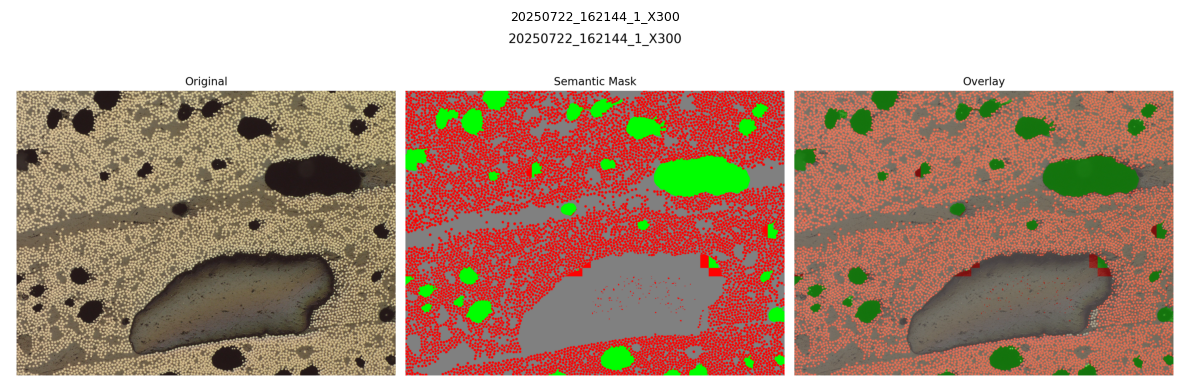

✅ Summary grid → outputs\ALL_summary.png


In [1]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import os
import math
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from skimage.measure import regionprops, label
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu
import scipy.ndimage as ndi

# =============================================================================
# CONFIGURATION
# =============================================================================
IMAGE_FOLDER   = "images"
OUTPUT_FOLDER  = "outputs"
SAM_CHECKPOINT = "Checkpoints/sam_vit_h_4b8939.pth"
IMAGE_EXTS     = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

# Patch settings — reduce PATCH_SIZE if you run out of GPU memory
PATCH_SIZE   = 512
OVERLAP      = 64    # larger overlap = smoother seams, but slower

# Threshold at which to switch from full-image to patch mode (pixels)
PATCH_THRESHOLD_PX = 600 * 600

COLORS = {
    0: [128, 128, 128],   # matrix → grey
    1: [255,   0,   0],   # fiber  → red
    2: [  0, 255,   0],   # void   → green
}

# =============================================================================
# 1. LOAD SAM
# =============================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

sam = sam_model_registry["vit_h"](checkpoint=SAM_CHECKPOINT)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=128,
    pred_iou_thresh=0.7,
    stability_score_thresh=0.8,
    min_mask_region_area=5
)

# =============================================================================
# 2. PATCH UTILITIES
# =============================================================================

def extract_patches(img, patch_size=512, overlap=64):
    """Split image into overlapping patches. Returns list of (x, y, patch)."""
    patches = []
    h, w = img.shape[:2]
    step = patch_size - overlap
    for y in range(0, h, step):
        for x in range(0, w, step):
            x_end = min(x + patch_size, w)
            y_end = min(y + patch_size, h)
            patches.append((x, y, img[y:y_end, x:x_end]))
    return patches, (h, w)


def merge_patches(patch_results, full_size):
    """
    Average overlapping patch masks and round to nearest label.
    Using float accumulation means border disagreements are resolved
    by majority vote rather than whichever patch was painted last.
    """
    h, w = full_size
    accum  = np.zeros((h, w), dtype=np.float32)
    weight = np.zeros((h, w), dtype=np.float32)
    for (x, y, patch_mask) in patch_results:
        y_end = y + patch_mask.shape[0]
        x_end = x + patch_mask.shape[1]
        accum [y:y_end, x:x_end] += patch_mask.astype(np.float32)
        weight[y:y_end, x:x_end] += 1.0
    averaged = accum / np.maximum(weight, 1e-8)
    return np.round(averaged).astype(np.uint8)

# =============================================================================
# 3. CORE SEGMENTATION (fixed thresholds — works on one patch OR full image)
# =============================================================================

def segment_tile(img_rgb, gray):
    """
    Run SAM + classify on a single tile (patch or full image).
    Returns semantic mask (H, W) uint8: 0=matrix, 1=fiber, 2=void.
    """
    masks = mask_generator.generate(img_rgb)

    regions = []
    for m in masks:
        bin_mask = m["segmentation"].astype(np.uint8)
        labeled  = label(bin_mask)
        for p in regionprops(labeled, intensity_image=gray):
            if p.area < 5:
                continue
            perim = p.perimeter if p.perimeter > 1e-8 else 1.0
            circularity = (4 * math.pi * p.area) / (perim**2 + 1e-8)
            regions.append({
                "mask":        (labeled == p.label),
                "area":        p.area,
                "circularity": circularity,
            })

    if not regions:
        return np.zeros(gray.shape, dtype=np.uint8)

    # --- Thresholds (fixed formula — robust to extreme pixels) ---
    areas          = np.array([r["area"] for r in regions])
    fiber_area_max = max(10, np.percentile(areas, 50))
    void_area_min  = fiber_area_max * 10        # voids are much larger than beads
    otsu_thresh    = threshold_otsu(gray)
    dark_threshold = otsu_thresh * 0.5          # only truly black pixels
    fiber_thresh   = otsu_thresh                # beads must be brighter than matrix

    # --- Classify ---
    h, w          = gray.shape
    semantic_mask = np.zeros((h, w), dtype=np.uint8)

    for r in sorted(regions, key=lambda r: r["area"], reverse=True):
        px          = gray[r["mask"]]
        dark_frac   = np.sum(px < dark_threshold) / len(px)
        mean_val    = np.mean(px)

        if r["area"] >= void_area_min and dark_frac >= 0.7:
            label_id = 2                                      # void
        elif r["area"] <= fiber_area_max * 3:
            if r["circularity"] > 0.65 and mean_val > fiber_thresh:
                label_id = 1                                  # fiber (small + round + bright)
            else:
                label_id = 0                                  # matrix
        else:
            label_id = 0                                      # matrix

        semantic_mask[np.logical_and(r["mask"], semantic_mask == 0)] = label_id

    # --- Cleanup ---
    for cls in (1, 2):
        cleaned = ndi.binary_opening(semantic_mask == cls, structure=np.ones((3, 3)))
        cleaned = ndi.binary_fill_holes(cleaned)
        semantic_mask[semantic_mask == cls] = 0
        semantic_mask[cleaned] = cls

    return semantic_mask

# =============================================================================
# 4. SMART DISPATCHER — full image or patch mode based on image size
# =============================================================================

def segment_image(img_rgb):
    """
    Automatically choose full-image or patch mode based on image size.
    Small images → processed in one shot (faster, no seam artifacts).
    Large images → split into patches (avoids GPU memory issues with SAM).
    """
    gray    = (rgb2gray(img_rgb) * 255).astype(np.uint8)
    h, w    = img_rgb.shape[:2]
    n_px    = h * w

    if n_px <= PATCH_THRESHOLD_PX:
        print(f"  Image {w}×{h} — full-image mode")
        return segment_tile(img_rgb, gray)

    # Patch mode
    patches, full_size = extract_patches(img_rgb, PATCH_SIZE, OVERLAP)
    print(f"  Image {w}×{h} — patch mode ({len(patches)} patches, size={PATCH_SIZE}, overlap={OVERLAP})")

    patch_results = []
    for i, (x, y, patch_rgb) in enumerate(patches):
        print(f"    Patch {i+1}/{len(patches)} at ({x},{y}) size={patch_rgb.shape[1]}×{patch_rgb.shape[0]}")
        patch_gray = (rgb2gray(patch_rgb) * 255).astype(np.uint8)
        patch_mask = segment_tile(patch_rgb, patch_gray)
        patch_results.append((x, y, patch_mask))

    return merge_patches(patch_results, full_size)

# =============================================================================
# 5. VISUALIZATION & SAVING
# =============================================================================

def save_results(img_rgb, semantic_mask, out_dir, stem):
    color_mask = np.zeros((*semantic_mask.shape, 3), dtype=np.uint8)
    for cls, col in COLORS.items():
        color_mask[semantic_mask == cls] = col

    overlay = cv2.addWeighted(img_rgb, 0.6, color_mask, 0.4, 0)

    plt.imsave(os.path.join(out_dir, f"{stem}_original.png"),      img_rgb)
    plt.imsave(os.path.join(out_dir, f"{stem}_semantic_mask.png"), color_mask)
    plt.imsave(os.path.join(out_dir, f"{stem}_overlay.png"),       overlay)
    cv2.imwrite(os.path.join(out_dir, f"{stem}_mask_raw.png"),     semantic_mask)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(stem, fontsize=14)
    for ax, img, title in zip(axes,
                               [img_rgb, color_mask, overlay],
                               ["Original", "Semantic Mask", "Overlay"]):
        ax.imshow(img); ax.set_title(title); ax.axis("off")
    plt.tight_layout()
    panel_path = os.path.join(out_dir, f"{stem}_comparison.png")
    plt.savefig(panel_path, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"  Saved → {panel_path}")

    total = semantic_mask.size
    for cls, name in [(0, "matrix"), (1, "fiber"), (2, "void")]:
        px = np.sum(semantic_mask == cls)
        print(f"    {name:8s}: {px:>10,} px  ({100*px/total:.1f}%)")

# =============================================================================
# 6. BATCH LOOP
# =============================================================================
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

image_files = sorted([f for f in os.listdir(IMAGE_FOLDER)
                       if f.lower().endswith(IMAGE_EXTS)])

if not image_files:
    raise FileNotFoundError(f"No images found in '{IMAGE_FOLDER}'")

print(f"\nFound {len(image_files)} image(s).\n")

for fname in image_files:
    stem = os.path.splitext(fname)[0]
    print(f"▶ {fname}")
    img_bgr = cv2.imread(os.path.join(IMAGE_FOLDER, fname))
    if img_bgr is None:
        print(f"  ⚠ Could not read, skipping."); continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    try:
        semantic_mask = segment_image(img_rgb)
        save_results(img_rgb, semantic_mask, OUTPUT_FOLDER, stem)
        print(f"  ✅ Done\n")
    except Exception as e:
        print(f"  ❌ Failed: {e}\n")

# =============================================================================
# 7. SUMMARY GRID
# =============================================================================
panel_files = sorted([f for f in os.listdir(OUTPUT_FOLDER)
                       if f.endswith("_comparison.png")])
if panel_files:
    ncols = min(len(panel_files), 2)
    nrows = math.ceil(len(panel_files) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 12, nrows * 5))
    axes = np.array(axes).flatten()
    for ax, pf in zip(axes, panel_files):
        ax.imshow(plt.imread(os.path.join(OUTPUT_FOLDER, pf)))
        ax.set_title(pf.replace("_comparison.png", ""), fontsize=9)
        ax.axis("off")
    for ax in axes[len(panel_files):]:
        ax.axis("off")
    plt.tight_layout()
    summary = os.path.join(OUTPUT_FOLDER, "ALL_summary.png")
    plt.savefig(summary, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"✅ Summary grid → {summary}")